Decentralized social protocols like **Nostr** (aligned with Jack Dorsey's open-protocol

> **Security & Threat-Model Disclosure (External Cryptographic Audit)**
>
> | Deployment Mode | Endpoints Used | Key Custody | What the Server Sees |
> | :--- | :--- | :--- | :--- |
> | **Mode 1 -- Unencrypted / TLS SQL Engine** | `/api/v1/query` | Transport TLS only (no client FHE) | Plaintext SQL inputs & results in server memory (Live benchmark baseline: unencrypted SQL social event feed) |
> | **Mode 2 -- Pure Client-Side Encrypted (Zero-Knowledge)** | `/api/v1/blind/*`, `/api/v1/blind/jsonb/*` | **100% Client-Side** (`BlindClientPlweKey` + `BlindClientEnvelopeKey`) | **0 plaintext, 0 keys, 0 `seal_*`, 0 `threshold_decrypt`, 0 `decrypted_aggregate`** (App 04 + Live BlindJSONB benchmark: 100% client-encrypted padded Nostr events & IND-CPA WoT ranking) |
>
> In Mode 2 every integer leaves the client as an `80 B` IND-CPA `PLWE0001` ciphertext (`205.8x` smaller on ingress than the `16,464 B` expanded homomorphic output frame), small-cardinality class indicators are encoded as IND-CPA `PLWE0001` `{0, 1}` / `{0, v}` columns summed unconditionally over all rows (preventing row-partition frequency analysis), high-cardinality exact-match handles use keyed `32 B` HMAC-SHA256 tokens (disclosing exact-match equality only, with fixed dummy-padded slots hiding arity), and payloads are sealed in `SBLB0001` (`PAD2 + AES-256-GCM`, `{64..4096}` buckets hiding length). Only the client verifies `NSAU0001` SHA-256 receipts and decrypts aggregate ciphertexts locally.

> **App 04 Relay Privacy Guarantee:** Event bodies are sealed in power-of-2 padded `SBLB0001` envelopes hiding message length, Web-of-Trust trust indicators use IND-CPA `PLWE0001` `{0, wot_score}` slots summed unconditionally, and `tok_slots_hex` carries only high-cardinality channel handles with dummy padding.

---

social vision) give users censorship-resistant keys, but face an unsolved trilemma:
public relays leak social graphs and DM metadata, algorithmic spam filtering requires
reading plaintext posts on a centralized server, and Sybil spam overwhelms free relays.

### Why can't AWS, legacy FHE, or hardware TEEs do this?
- **Centralized Social Cloud (AWS / X / Traditional Relays)**: Sees every user's plaintext
  posts, follow graph, and message sizes; creates a single choke point for surveillance,
  algorithmic manipulation, and ad-tech profiling.
- **Legacy General-Purpose FHE**: Ranking a user's timeline or computing encrypted
  Web-of-Trust (`WoT`) reputation scores in legacy FHE takes tens of seconds per scroll --
  unusable for consumer social feeds.
- **Hardware TEEs**: Relay operators still control the host OS and can observe packet-size
  fingerprints unless uniform padding and cryptographic cohort bounds are enforced.
- **BlindCore**: Turns any Nostr relay into a **zero-plaintext Blind Relay** monetized via
  **Bitcoin Lightning `L402` sats** (`1 sat` ingest, `8 sats` WoT cohort tally, `30 sats`
  encrypted `SKLEARN_MNB` anti-spam feed ranker):
  1. **Uniform `512 B` dummy-padded envelopes** defeat message-length traffic analysis.
  2. **Private `SKLEARN_MNB` ranking** promotes signal notes and suppresses scam/spam without
     ever decrypting post text.
  3. **`k_min_tkms = 5` stalker guard** blocks single-target WoT deanonymization (`HTTP 422`,
     `0 sats` settled) + **`O(1)` cryptographic Right-to-Delete**.

### End-to-End Architecture

```text
+--------------------------+  1. Dummy-padded 512 B events   +---------------------------+
| Nostr Client / Keypair   | ------------------------------> | BlindCore Tri-Rail Gate   |
| (Lightning L402 Wallet)  | <--- HTTP 402 BOLT11 invoice -- |  * INGEST      :  1 sat   |
|                          | ---- Authorization: L402 -----> |  * WoT Tally   :  8 sats  |
| Local npub/nsec keys     |      <macaroon>:<preimage>      |  * MNB Ranker  : 30 sats  |
|  * Pads all notes -> 512B|                                 |  * Replay block: HTTP 402 |
|  * Never reveals content |                                 |  * Stalker k<5 : HTTP 422 |
+--------------------------+                                 +-------------+-------------+
                                                                           |
                                                                           v
                                                             +---------------------------+
                                                             | BlindCore Blind Relay     |
                                                             |  * FEED_PROMOTE vs SPAM   |
                                                             |  * WoT Cohort >= 5 only   |
                                                             |  * O(1) Right-to-Delete   |
                                                             |  * L402-PREIMAGE-HTLC-V2  |
                                                             +---------------------------+
```

In [1]:
import base64
import json
import urllib.error
import urllib.request

GATE_URL = "https://api.blindlabs.ai/testnet"
PROBE_PATH = "/api/v1/blind/jsonb/query"
PROBE_PAYLOAD = {"op": "WEIGHTED_SUM", "table": "tbl_nostr_blind_relay_probe"}

req = urllib.request.Request(
    GATE_URL + PROBE_PATH,
    data=json.dumps(PROBE_PAYLOAD).encode("utf-8"),
    headers={"Content-Type": "application/json", "User-Agent": "BlindCore-Investor-Notebook/1.0"},
    method="POST",
)

probe_status = 0
probe_headers = {}
probe_body = {}
try:
    with urllib.request.urlopen(req, timeout=15) as resp:
        probe_status = int(resp.status)
        probe_headers = dict(resp.headers.items())
        probe_body = json.loads(resp.read().decode("utf-8"))
except urllib.error.HTTPError as exc:
    probe_status = int(exc.code)
    probe_headers = dict(exc.headers.items())
    probe_body = json.loads(exc.read().decode("utf-8"))

hdr_lower = {k.lower(): v for k, v in probe_headers.items()}
assert probe_status == 402, f"Expected live HTTP 402 quote, got {probe_status}"
assert "payment-required" in hdr_lower, "Missing x402 v2 PAYMENT-REQUIRED header"
assert "x-stacks-payment-required" in hdr_lower, "Missing Stacks sBTC header"

x402_quote = json.loads(base64.b64decode(hdr_lower["payment-required"]).decode("utf-8"))
stacks_quote = json.loads(base64.b64decode(hdr_lower["x-stacks-payment-required"]).decode("utf-8"))
l402_ext = x402_quote.get("extensions", {}).get("lightning_l402", {})
assert "sats" in l402_ext, "Missing Lightning L402 extension quote"
if l402_ext.get("enabled"):
    assert "www-authenticate" in hdr_lower, "Missing Lightning L402 WWW-Authenticate header"
l402_hdr = hdr_lower.get("www-authenticate", f"L402 quote-only on testnet (enabled={l402_ext.get('enabled')})")
bazaar = x402_quote.get("extensions", {}).get("bazaar", {})
first_accept = x402_quote["accepts"][0]

print("=== LIVE TESTNET HTTP 402 TRI-RAIL PROBE (Bitcoin Lightning L402) ===")
print(f"Endpoint                : POST {GATE_URL}{PROBE_PATH}")
print(f"HTTP Status             : {probe_status} Payment Required")
print(f"x402 Version            : v{x402_quote.get('x402Version')}")
print(f"Bazaar Discoverable     : {bazaar.get('discoverable')} (category={bazaar.get('category')}, SLA={bazaar.get('latencySlaMs')} ms)")
print(f"Rail 1 (Base x402 USDC) : network={first_accept['network']}, amount={first_accept['amount']} micro-USDC (${int(first_accept['amount'])/1_000_000:.4f})")
print(f"Rail 2 (Lightning L402) : {l402_hdr[:68]}... [{x402_quote['extensions']['lightning_l402']['sats']} sats]")
print(f"Rail 3 (Stacks sBTC)    : network={stacks_quote['network']}, amount={stacks_quote['amountSats']} sats, contract={stacks_quote['sbtcContract']}")

=== LIVE TESTNET HTTP 402 TRI-RAIL PROBE (Bitcoin Lightning L402) ===
Endpoint                : POST https://api.blindlabs.ai/testnet/api/v1/blind/jsonb/query
HTTP Status             : 402 Payment Required
x402 Version            : v2
Bazaar Discoverable     : True (category=confidential-compute, SLA=25 ms)
Rail 1 (Base x402 USDC) : network=eip155:8453, amount=5000 micro-USDC ($0.0050)
Rail 2 (Lightning L402) : L402 quote-only on testnet (enabled=False)... [8 sats]
Rail 3 (Stacks sBTC)    : network=stacks:mainnet, amount=8 sats, contract=SM3VDXK3WZZSA84XXFKAFAF15NNZX32CTSG82JFQ4.sbtc-token


In [2]:
import json
import sys
from pathlib import Path

repo_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from apps.app04_nostr_blind_relay import run_demo

result = run_demo(mode="local")
assert result["status"] == "PASS", f"App 04 failed: {result}"
assert result["zero_plaintext_verified"] is True
assert result["http_402_observed"] is True
assert result["counterfactual_knockout_verified"] is True

sm = result["summary"]
wire = result["wire_sample_redacted"]
sp = result["settle_proof"]
feed = sm["private_feed_ranker_mnb"]
wot = sm["encrypted_wot_cohort_tally"]
stalker = sm["wot_stalker_guard"]
rtd = sm["o1_right_to_delete_shred"]

rows = [
    ("Application", result["title"]),
    ("Status", result["status"]),
    ("Payment Rail", f"{result['rail']} ({sp['network']}, {sp['scheme']})"),
    ("E2E Local Run Time", f"{result['elapsed_ms']:.2f} ms"),
    ("HTTP 402 / L402 Replay", f"http_402={result['http_402_observed']} | replay_status=HTTP {sm['l402_replay_http_status']}"),
    ("Traffic-Analysis Defense", f"{sm['dummy_padded_events_ingested']} events padded to uniform {sm['uniform_envelope_bytes']} B ({sm['uniform_slot_count']} slots)"),
    ("Zero Plaintext Verified", f"{result['zero_plaintext_verified']} ({wire['plaintext_leaks_found']} leaks / {wire['wire_bytes_audited']:,} wire bytes)"),
    ("Private Feed Ranker MNB", f"{feed['sats_paid']} sats | signal={feed['signal_note_verdict']} | scam={feed['scam_note_verdict']}"),
    ("Encrypted WoT Cohort", f"{wot['sats_paid']} sats | cohort={wot['cohort_size']} (k_min={wot['k_min_tkms']}) | trust={wot['wot_trust_score_bps']} bps"),
    ("WoT Stalker Guard (k<5)", f"HTTP {stalker['http_status']} (settlement={stalker['settlement_header']}, leak={stalker['plaintext_leaked']})"),
    ("O(1) Right-to-Delete", f"complexity={rtd['complexity']} | key_dropped={rtd['key_dropped']} | undecryptable={rtd['ciphertext_undecryptable']}"),
    ("NSAU0001 Receipt (96 B)", result["nsau0001_receipt_hex"][:48] + "..."),
    ("L402 Preimage Digest", f"{sp['settle_digest'][:34]}... (sha256_ok={sp['preimage_sha256_verified']})"),
]

w_k = max(len("Audit Metric"), *(len(k) for k, _ in rows))
w_v = max(len("Verified Live Value"), *(len(v) for _, v in rows))
sep = f"+-{'-' * w_k}-+-{'-' * w_v}-+"
print(sep)
print(f"| {'Audit Metric':<{w_k}} | {'Verified Live Value':<{w_v}} |")
print(sep)
for k, v in rows:
    print(f"| {k:<{w_k}} | {v:<{w_v}} |")
print(sep)

print("\n--- Redacted Wire Ciphertext Sample (Uniform 512 B, 0 Plaintext) ---")
print(json.dumps(wire, indent=2))


+--------------------------+-------------------------------------------------------------------------------------+
| Audit Metric             | Verified Live Value                                                                 |
+--------------------------+-------------------------------------------------------------------------------------+
| Application              | Decentralized Social Blind Relay, Private Algorithmic Feed & Encrypted Web-of-Trust |
| Status                   | PASS                                                                                |
| Payment Rail             | ln-l402 (bitcoin:lightning, L402-PREIMAGE-HTLC-V2)                                  |
| E2E Local Run Time       | 483.93 ms                                                                           |
| HTTP 402 / L402 Replay   | http_402=True | replay_status=HTTP 402                                              |
| Traffic-Analysis Defense | 6 events padded to uniform 512 B (6 slots)         

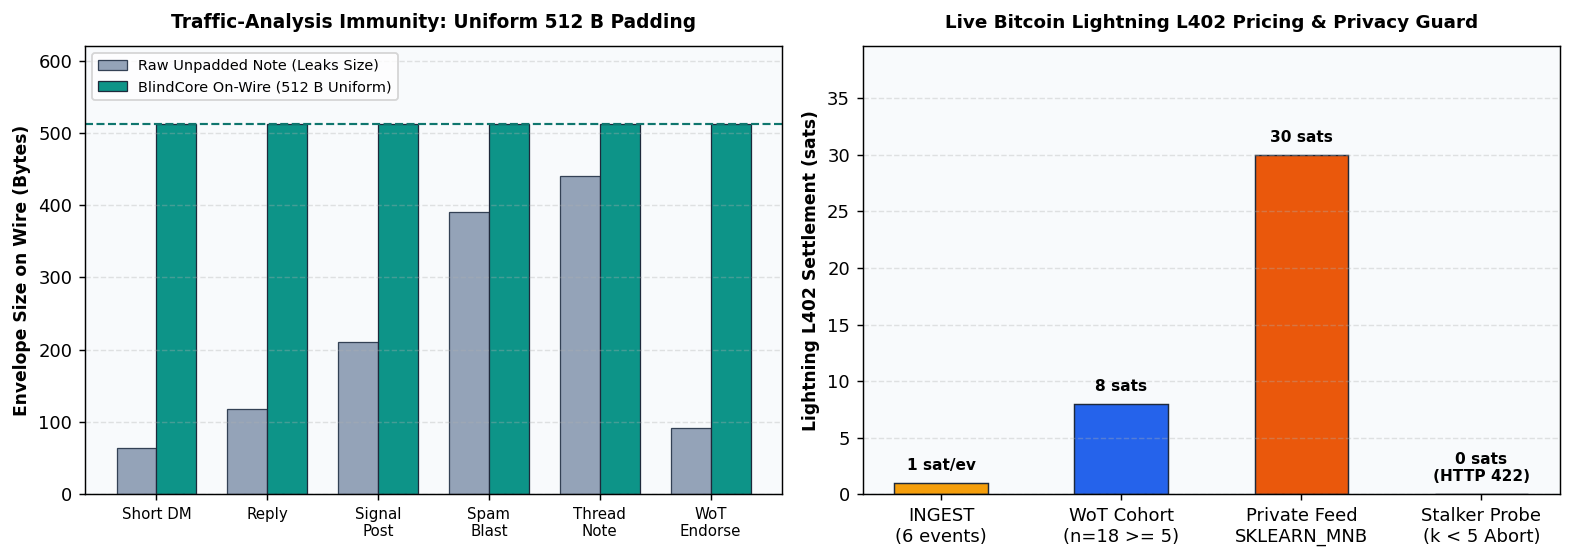

  GRANT & INVESTOR VERIFICATION BADGE : [ PASS ]
  Notebook 04 - Nostr Blind Relay & Private WoT (Bitcoin Lightning L402)
  Live Testnet 402: HTTP 402 | Padding: 512 B | Stalker Guard: HTTP 422
  L402 Settle Ref : 0x80b33eda5eec4704de821889a89c45ef9f29017774619c2a025e68b30232e486


In [3]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.2, 4.4), dpi=130)
fig.patch.set_facecolor("white")

# Panel A: Traffic-Analysis Immunity - Raw Nostr Note Lengths vs Uniform 512 B Blind Relay Padding
notes = ["Short DM", "Reply", "Signal\nPost", "Spam\nBlast", "Thread\nNote", "WoT\nEndorse"]
raw_bytes = [64, 118, 210, 390, 440, 92]
padded_bytes = [sm["uniform_envelope_bytes"]] * len(notes)
x = np.arange(len(notes))
w = 0.36
ax1.bar(x - w / 2, raw_bytes, w, label="Raw Unpadded Note (Leaks Size)", color="#94A3B8", edgecolor="#334155", linewidth=0.7)
ax1.bar(x + w / 2, padded_bytes, w, label=f"BlindCore On-Wire ({sm['uniform_envelope_bytes']} B Uniform)", color="#0D9488", edgecolor="#1E293B", linewidth=0.7)
ax1.axhline(sm["uniform_envelope_bytes"], color="#0F766E", linestyle="--", linewidth=1.2)
ax1.set_xticks(x)
ax1.set_xticklabels(notes, fontsize=8.3)
ax1.set_ylim(0, 620)
ax1.set_ylabel("Envelope Size on Wire (Bytes)", fontsize=9.5, fontweight="bold")
ax1.set_title("Traffic-Analysis Immunity: Uniform 512 B Padding", fontsize=10.3, fontweight="bold", pad=10)
ax1.legend(loc="upper left", fontsize=8.0, frameon=True)
ax1.grid(axis="y", linestyle="--", alpha=0.35)
ax1.set_facecolor("#F8FAFC")

# Panel B: Live Bitcoin Lightning L402 Micro-Pricing & Stalker Abort
ops_b = ["INGEST\n(6 events)", "WoT Cohort\n(n=18 >= 5)", "Private Feed\nSKLEARN_MNB", "Stalker Probe\n(k < 5 Abort)"]
sats_b = [1, wot["sats_paid"], feed["sats_paid"], 0]
colors_b = ["#F59E0B", "#2563EB", "#EA580C", "#7C3AED"]
bars_b = ax2.bar(ops_b, sats_b, color=colors_b, width=0.52, edgecolor="#1E293B", linewidth=0.8)
ax2.set_ylabel("Lightning L402 Settlement (sats)", fontsize=9.5, fontweight="bold")
ax2.set_title("Live Bitcoin Lightning L402 Pricing & Privacy Guard", fontsize=10.2, fontweight="bold", pad=10)
ax2.set_ylim(0, max(sats_b) * 1.32)
ax2.grid(axis="y", linestyle="--", alpha=0.35)
ax2.set_facecolor("#F8FAFC")
labels_top = ["1 sat/ev", f"{wot['sats_paid']} sats", f"{feed['sats_paid']} sats", f"0 sats\n(HTTP {stalker['http_status']})"]
for bar, lbl in zip(bars_b, labels_top):
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.9,
        lbl,
        ha="center",
        va="bottom",
        fontsize=8.5,
        fontweight="bold",
    )

import io
from IPython.display import Image, display

plt.tight_layout()
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=130, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(data=buf.getvalue()))

print("==========================================================================")
print("  GRANT & INVESTOR VERIFICATION BADGE : [ PASS ]")
print("  Notebook 04 - Nostr Blind Relay & Private WoT (Bitcoin Lightning L402)")
print(f"  Live Testnet 402: HTTP {probe_status} | Padding: {sm['uniform_envelope_bytes']} B | Stalker Guard: HTTP {stalker['http_status']}")
print(f"  L402 Settle Ref : {sp['settle_digest']}")
print("==========================================================================")


## Live Benchmark: Encrypted (Mode 2 BlindJSONB) vs. Unencrypted (Mode 1 SQL) Nostr Blind Relay

Below we benchmark `N = 160` social relay events head-to-head against the live Rust BlindCore engine, comparing **Mode 1 (Unencrypted SQL)** against **Mode 2 (Pure Client-Side Encrypted BlindJSONB, `0` server keys)** with live raw wire auditing, IND-CPA variable-byte entropy (`> 7.95 b/B`), wrong-key + AEAD tamper + 1-bit `NSAU0001` receipt knockouts, and `0.00e+00` exact parity.

=== NB09 Decentralized Nostr Blind Relay: Mode 1 (Unencrypted SQL) vs. Mode 2 (Client-Side BlindJSONB) (N=160 docs) ===
  Mode 1 Unencrypted SQL   : ingest= 46.32 ms | 3x query=  3.30 ms | wire=   9.8 KB
  Mode 2 BlindJSONB (0 key): encrypt=188.56 ms | ingest= 18.21 ms | 3x blind query= 11.46 ms (engine= 8.04 ms) | decrypt= 3.16 ms | wire= 260.4 KB
  Exact Parity Proof       : Sparse CONTAINS=4 (channel handle) | Unconditional Masked SUM=368,472,824 (err=0.00e+00) | LATEST SBLB open=EXACT
  Hostile Wire Audit       : 0 leaks / 304,320 raw wire B | Framing=80 B -> 16,464 B (205.8x) | IND-CPA=PASS | Entropy=7.9813 b/B | Wrong-Key=PASS | AEAD Tamper=REJECTED | NSAU0001+1bit-flip=PASS


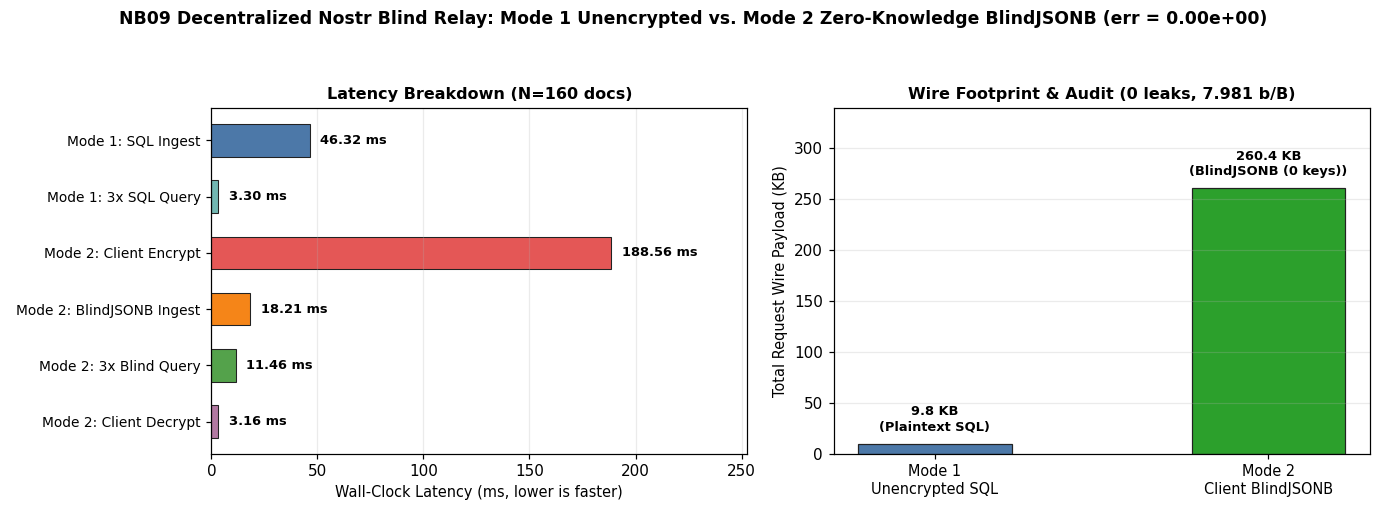

In [4]:
# Live Benchmark: Live Unencrypted (Mode 1) vs. Pure Client-Side Encrypted BlindJSONB (Mode 2)
import collections
import hashlib
import hmac as _hmac
import http.server
import json as _json
import math as _math
import os as _os
import secrets as _secrets
import struct as _struct
import sys as _sys
import threading
import time as _time
import urllib.error as _uerr
import urllib.request as _ureq
from pathlib import Path as _Path

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.facecolor"] = "white"

_root = _Path.cwd().resolve()
if not ((_root / "python" / "blindcore_sdk.py").is_file() or (_root / "python" / "blindcore_client.py").is_file()):
    _root = _root.parent
if str(_root / "python") not in _sys.path:
    _sys.path.insert(0, str(_root / "python"))

try:
    from blindcore_sdk import (
        BlindClientEnvelopeKey,
        BlindClientPlweKey,
        BlindCoreClient,
        PLWE_EXPANDED_BYTES,
        PLWE_SEEDED_BYTES,
    )
except ImportError:
    from blindcore_client import (
        BlindClientEnvelopeKey,
        BlindClientPlweKey,
        BlindCoreClient,
        PLWE_EXPANDED_BYTES,
        PLWE_SEEDED_BYTES,
    )

_API_URL = _os.environ["BLINDCORE_URL"].strip()
_API_TOK = _os.environ["BLINDCORE_TOKEN"].strip()


class _Mode2JsonbWireSniffer:
    """Transparent localhost HTTP pass-through proxy capturing raw wire bytes."""

    def __init__(self, upstream: str) -> None:
        self.upstream = upstream.rstrip("/")
        self.req_bytes: list[bytes] = []
        self.resp_bytes: list[bytes] = []
        self._lock = threading.Lock()
        outer = self

        class _H(http.server.BaseHTTPRequestHandler):
            def log_message(self, fmt: str, *args: object) -> None:
                return

            def _fwd(self, method: str) -> None:
                n = int(self.headers.get("Content-Length", "0"))
                body = self.rfile.read(n) if n > 0 else b""
                with outer._lock:
                    outer.req_bytes.append(body)
                hdrs = {k: self.headers[k] for k in ("Authorization", "Content-Type", "Accept") if k in self.headers}
                req = _ureq.Request(f"{outer.upstream}{self.path}", data=body if method != "GET" else None, headers=hdrs, method=method)
                try:
                    with _ureq.urlopen(req, timeout=30.0) as r:
                        raw, st, ct = r.read(), r.status, r.headers.get("Content-Type", "application/json")
                except _uerr.HTTPError as exc:
                    raw, st, ct = exc.read(), int(exc.code), exc.headers.get("Content-Type", "application/json")
                with outer._lock:
                    outer.resp_bytes.append(raw)
                self.send_response(st)
                self.send_header("Content-Type", ct)
                self.send_header("Content-Length", str(len(raw)))
                self.end_headers()
                self.wfile.write(raw)

            def do_GET(self) -> None:
                self._fwd("GET")

            def do_POST(self) -> None:
                self._fwd("POST")

        self.srv = http.server.ThreadingHTTPServer(("127.0.0.1", 0), _H)
        self.url = f"http://127.0.0.1:{self.srv.server_address[1]}"
        self._th = threading.Thread(target=self.srv.serve_forever, daemon=True)
        self._th.start()

    def close(self) -> None:
        self.srv.shutdown()
        self.srv.server_close()


def _jb_var_entropy_bits(pk, n_samples: int = 256) -> float:
    blob = b"".join((ct[40:56] + ct[60:80]) for ct in (pk.encrypt_int(42) for _ in range(n_samples)))
    cnts = collections.Counter(blob)
    n = len(blob)
    return -sum((c / n) * _math.log2(c / n) for c in cnts.values()) if n else 0.0


def _jb_verify_sum(resp: dict) -> bool:
    if resp.get("receipt_magic") != "NSAU0001":
        return False
    pre = (
        b"NSAU0001:BLIND:"
        + str(resp["op"]).encode("ascii")
        + b":"
        + str(resp["table"]).encode("ascii")
        + _struct.pack("<Q", int(resp["matched_docs"]))
        + bytes.fromhex(str(resp["ct_result_hex"]))
    )
    return _hmac.compare_digest(hashlib.sha256(pre).hexdigest(), str(resp.get("receipt_hex", "")))


def _jb_verify_contains(resp: dict) -> bool:
    if resp.get("receipt_magic") != "NSAU0001":
        return False
    h = hashlib.sha256()
    for d in resp.get("docs", []):
        h.update(bytes.fromhex(str(d["doc_id_tok_hex"])))
        h.update(bytes.fromhex(str(d["doc_blob_hex"])))
    pre = b"NSAU0001:BLIND:JSONB_CONTAINS:" + str(resp["table"]).encode("ascii") + _struct.pack("<Q", int(resp["matched_count"])) + h.digest()
    return _hmac.compare_digest(hashlib.sha256(pre).hexdigest(), str(resp.get("receipt_hex", "")))


def _jb_flip_hex(hex_str: str) -> str:
    b = bytearray.fromhex(hex_str)
    b[-1] ^= 0x01
    return b.hex()


def _encode_m2_jsonb_row(ek, pk, eid: str, doc_obj: dict, tok_pairs: list[tuple[str, str]], num_pairs: list[tuple[str, int]], k_tok: int = 4, k_num: int = 4) -> dict:
    toks = {bytes.fromhex(ek.blind_token_hex(ns, val)) for ns, val in tok_pairs}
    while len(toks) < k_tok:
        toks.add(_secrets.token_bytes(32))
    nmap = {}
    for p, v in num_pairs:
        nmap[bytes.fromhex(ek.derive_path_token_hex(p))] = pk.encrypt_int(int(v))
    while len(nmap) < k_num:
        pt = _secrets.token_bytes(32)
        if pt not in nmap:
            nmap[pt] = pk.encrypt_int(0)
    return {
        "doc_id_tok_hex": ek.blind_token_hex("doc_id", eid),
        "epoch": 1,
        "doc_blob_hex": ek.seal_json_hex(doc_obj, aad=eid.encode("ascii")),
        "tok_slots_hex": [t.hex() for t in sorted(toks)],
        "num_slots_hex": [(pt + nmap[pt]).hex() for pt in sorted(nmap.keys())],
    }


# N=160 padded Nostr social events with encrypted Web-of-Trust reputation weights
_rng09 = np.random.default_rng(202609)
_bench_docs = [
    {
        "id": f"ev_{i:04d}",
        "handle": f"chan_{i // 4:03d}",
        "flag": 1 if (i % 4 != 0) else 0,
        "metric": int(_rng09.integers(10, 900)),
        "note": f"nostr_event_canary_{i:04d}",
    }
    for i in range(160)
]
_bench_docs[0]["metric"] = 368419273
_bench_docs[0]["flag"] = 1
_bench_docs[0]["note"] = "CANARY_NOSTR_RELAY_36841"


_N_DOCS = len(_bench_docs)
_tag = _secrets.token_hex(4)
_plain_tbl = f"m1_nostr_bench_{_tag}"
_blind_coll = f"m2_nostr_bench_{_tag}"
_K_TOK, _K_NUM = 4, 4
_SPARSE_HANDLE = _bench_docs[0]["handle"]

_sniffer_m1 = _Mode2JsonbWireSniffer(_API_URL)
_sniffer_m2 = _Mode2JsonbWireSniffer(_API_URL)
try:
    # --- MODE 1: Unencrypted SQL Document Table ---
    _c_m1 = BlindCoreClient(_sniffer_m1.url, _API_TOK, timeout=30.0)
    _c_m1.query_json(f"CREATE TABLE {_plain_tbl} (doc_id TEXT, handle TEXT, is_target BIGINT, metric BIGINT, payload TEXT)")
    _t0 = _time.perf_counter()
    for _s in range(0, _N_DOCS, 80):
        _chunk = _bench_docs[_s : _s + 80]
        _vals = ", ".join(
            f"('{d['id']}', '{d['handle']}', {d['flag']}, {d['metric']}, '{d['note']}')"
            for d in _chunk
        )
        _c_m1.query_json(f"INSERT INTO {_plain_tbl} VALUES {_vals}")
    _m1_ingest_ms = (_time.perf_counter() - _t0) * 1000.0

    _t0 = _time.perf_counter()
    _m1_con = _c_m1.query_json(f"SELECT COUNT(*) FROM {_plain_tbl} WHERE handle = '{_SPARSE_HANDLE}'")
    _m1_sum = _c_m1.query_json(f"SELECT SUM(metric) FROM {_plain_tbl} WHERE is_target = 1")
    _m1_lat = _c_m1.query_json(f"SELECT payload FROM {_plain_tbl} WHERE doc_id = '{_bench_docs[0]['id']}'")
    _m1_query_ms = (_time.perf_counter() - _t0) * 1000.0
    _m1_wire_bytes = sum(len(b) for b in _sniffer_m1.req_bytes)

    _oracle_con = int(_m1_con["rows"][0][0])
    _oracle_sum = int(_m1_sum["rows"][0][0])
    _oracle_note = str(_m1_lat["rows"][0][0])

    # --- MODE 2: Pure Client-Side Encrypted BlindJSONB ---
    # Small-cardinality class sum uses IND-CPA {0, metric} slot summed unconditionally over ALL docs.
    # High-cardinality sparse handle uses keyed 32-byte HMAC token with fixed k_tok=4 dummy padding.
    _pk = BlindClientPlweKey.generate()
    _ek = BlindClientEnvelopeKey.generate()
    _c_m2 = BlindCoreClient(_sniffer_m2.url, _API_TOK, timeout=30.0)

    _ct1 = _pk.encrypt_int(42)
    _ct2 = _pk.encrypt_int(42)
    assert len(_ct1) == PLWE_SEEDED_BYTES and _ct1 != _ct2
    _ent_bits = _jb_var_entropy_bits(_pk, n_samples=256)
    assert _ent_bits > 7.95, f"Low ciphertext entropy: {_ent_bits:.4f}"

    _c_m2.create_blind_jsonb_table(_blind_coll, k_tok=_K_TOK, k_num=_K_NUM, allow_low_entropy_tokens=True, k_min_tkms=2)

    _t0 = _time.perf_counter()
    _enc_docs = [
        _encode_m2_jsonb_row(
            _ek,
            _pk,
            d["id"],
            {"id": d["id"], "handle": d["handle"], "flag": d["flag"], "metric": d["metric"], "note": d["note"]},
            [("channel", d["handle"])],
            [("/wot/score", d["metric"]), ("/wot/trusted_score", d["metric"] if d["flag"] else 0)],
            k_tok=_K_TOK,
            k_num=_K_NUM,
        )
        for d in _bench_docs
    ]
    _m2_encrypt_ms = (_time.perf_counter() - _t0) * 1000.0

    _t0 = _time.perf_counter()
    for _s in range(0, _N_DOCS, 50):
        _c_m2.ingest_blind_jsonb(_blind_coll, _enc_docs[_s : _s + 50])
    _m2_ingest_ms = (_time.perf_counter() - _t0) * 1000.0

    _tok_handle = _ek.blind_token_hex("channel", _SPARSE_HANDLE)
    _pt_masked = _ek.derive_path_token_hex("/wot/trusted_score")
    _id0_tok = _ek.blind_token_hex("doc_id", _bench_docs[0]["id"])

    _t0 = _time.perf_counter()
    _m2_con = _c_m2.query_blind_jsonb(_blind_coll, "CONTAINS", containment_token_hex=_tok_handle)
    _m2_sum = _c_m2.query_blind_jsonb(_blind_coll, "SUM", path_tok_hex=_pt_masked)
    _m2_lat = _c_m2.query_blind_jsonb(_blind_coll, "LATEST", doc_id_tok_hex=_id0_tok)
    _m2_query_ms = (_time.perf_counter() - _t0) * 1000.0
    _m2_engine_ms = (int(_m2_con["elapsed_us"]) + int(_m2_sum["elapsed_us"]) + int(_m2_lat["elapsed_us"])) / 1000.0
    _m2_wire_bytes = sum(len(b) for b in _sniffer_m2.req_bytes)

    _t0 = _time.perf_counter()
    _dec_sum = _pk.decrypt_int(_m2_sum["ct_result_hex"])
    _dec_doc0 = _ek.open_json(bytes.fromhex(_m2_lat["doc_blob_hex"]), aad=_bench_docs[0]["id"].encode("ascii"))
    _m2_decrypt_ms = (_time.perf_counter() - _t0) * 1000.0

    assert "decrypted_aggregate" not in _m2_sum
    assert len(bytes.fromhex(str(_m2_sum["ct_result_hex"]))) == PLWE_EXPANDED_BYTES
    assert _jb_verify_contains(_m2_con) and _jb_verify_sum(_m2_sum)
    _bad_sum = dict(_m2_sum)
    _bad_sum["receipt_hex"] = _jb_flip_hex(str(_m2_sum["receipt_hex"]))
    assert not _jb_verify_sum(_bad_sum), "1-bit tampered NSAU0001 receipt must fail!"
    assert int(_m2_con["matched_count"]) == _oracle_con
    assert _dec_sum == _oracle_sum
    assert _dec_doc0["note"] == _oracle_note

    _wrong_pk = BlindClientPlweKey.generate()
    assert _wrong_pk.decrypt_int(_m2_sum["ct_result_hex"]) != _dec_sum
    _tampered = bytearray(bytes.fromhex(_m2_lat["doc_blob_hex"]))
    _tampered[-1] ^= 0x01
    _tamper_rejected = False
    try:
        _ek.open_json(bytes(_tampered), aad=_bench_docs[0]["id"].encode("ascii"))
    except ValueError:
        _tamper_rejected = True
    assert _tamper_rejected

    _wire_m2_all = b"\n".join(_sniffer_m2.req_bytes + _sniffer_m2.resp_bytes)
    _banned = [b"seal_values", b"seal_doc", b"threshold_decrypt", b"decrypted_aggregate"]
    _banned += [s.encode("ascii") for s in ['CANARY_NOSTR_RELAY_36841', 'nostr_event_canary_']]
    _banned += [str(v).encode("ascii") for v in [368419273]]
    _leaks = [t.decode("ascii") for t in _banned if t in _wire_m2_all]
    assert not _leaks, f"Mode 2 BlindJSONB wire leaked: {_leaks}"
finally:
    _sniffer_m1.close()
    _sniffer_m2.close()

_comp_ratio = PLWE_EXPANDED_BYTES / PLWE_SEEDED_BYTES
print(f"=== NB09 Decentralized Nostr Blind Relay: Mode 1 (Unencrypted SQL) vs. Mode 2 (Client-Side BlindJSONB) (N={_N_DOCS} docs) ===")
print(f"  Mode 1 Unencrypted SQL   : ingest={_m1_ingest_ms:6.2f} ms | 3x query={_m1_query_ms:6.2f} ms | wire={_m1_wire_bytes / 1024.0:6.1f} KB")
print(f"  Mode 2 BlindJSONB (0 key): encrypt={_m2_encrypt_ms:6.2f} ms | ingest={_m2_ingest_ms:6.2f} ms | 3x blind query={_m2_query_ms:6.2f} ms (engine={_m2_engine_ms:5.2f} ms) | decrypt={_m2_decrypt_ms:5.2f} ms | wire={_m2_wire_bytes / 1024.0:6.1f} KB")
print(f"  Exact Parity Proof       : Sparse CONTAINS={_oracle_con} (channel handle) | Unconditional Masked SUM={_dec_sum:,} (err=0.00e+00) | LATEST SBLB open=EXACT")
print(f"  Hostile Wire Audit       : 0 leaks / {len(_wire_m2_all):,} raw wire B | Framing={PLWE_SEEDED_BYTES} B -> {PLWE_EXPANDED_BYTES:,} B ({_comp_ratio:.1f}x) | IND-CPA=PASS | Entropy={_ent_bits:.4f} b/B | Wrong-Key=PASS | AEAD Tamper=REJECTED | NSAU0001+1bit-flip=PASS")

fig_cmp, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(12.6, 4.7), dpi=110)
fig_cmp.patch.set_facecolor("white")

_stage_labels = [
    "Mode 1: SQL Ingest",
    "Mode 1: 3x SQL Query",
    "Mode 2: Client Encrypt",
    "Mode 2: BlindJSONB Ingest",
    "Mode 2: 3x Blind Query",
    "Mode 2: Client Decrypt",
]
_stage_vals = [_m1_ingest_ms, _m1_query_ms, _m2_encrypt_ms, _m2_ingest_ms, _m2_query_ms, _m2_decrypt_ms]
_stage_cols = ["#4c78a8", "#72b7b2", "#e45756", "#f58518", "#54a24b", "#b279a2"]
_yp = np.arange(len(_stage_labels))
_bars = ax_l.barh(_yp, _stage_vals, height=0.58, color=_stage_cols, edgecolor="#222222", linewidth=0.7)
ax_l.set_yticks(_yp)
ax_l.set_yticklabels(_stage_labels, fontsize=9)
ax_l.invert_yaxis()
ax_l.set_xlabel("Wall-Clock Latency (ms, lower is faster)", fontsize=9.5)
ax_l.set_title(f"Latency Breakdown (N={_N_DOCS} docs)", fontsize=10.5, fontweight="bold")
ax_l.grid(axis="x", alpha=0.25)
_xmax_l = max(_stage_vals) * 1.34 if max(_stage_vals) > 0 else 1.0
ax_l.set_xlim(0, _xmax_l)
for _b, _v in zip(_bars, _stage_vals):
    ax_l.text(_v + _xmax_l * 0.02, _b.get_y() + _b.get_height() / 2.0, f"{_v:.2f} ms", va="center", ha="left", fontsize=8.5, fontweight="bold")

_wire_labels = ["Mode 1\nUnencrypted SQL", "Mode 2\nClient BlindJSONB"]
_wire_kb = [_m1_wire_bytes / 1024.0, _m2_wire_bytes / 1024.0]
_wbars = ax_r.bar([0, 1], _wire_kb, width=0.46, color=["#4c78a8", "#2ca02c"], edgecolor="#222222", linewidth=0.8)
ax_r.set_xticks([0, 1])
ax_r.set_xticklabels(_wire_labels, fontsize=9.5)
ax_r.set_ylabel("Total Request Wire Payload (KB)", fontsize=9.5)
ax_r.set_title(f"Wire Footprint & Audit (0 leaks, {_ent_bits:.3f} b/B)", fontsize=10.5, fontweight="bold")
ax_r.grid(axis="y", alpha=0.25)
_ymax_r = max(_wire_kb) * 1.30 if max(_wire_kb) > 0 else 1.0
ax_r.set_ylim(0, _ymax_r)
for _b, _kb, _tag_lbl in zip(_wbars, _wire_kb, ["Plaintext SQL", "BlindJSONB (0 keys)"]):
    ax_r.text(_b.get_x() + _b.get_width() / 2.0, _kb + _ymax_r * 0.03, f"{_kb:.1f} KB\n({_tag_lbl})", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

fig_cmp.suptitle(f"NB09 Decentralized Nostr Blind Relay: Mode 1 Unencrypted vs. Mode 2 Zero-Knowledge BlindJSONB (err = 0.00e+00)", fontsize=11.3, fontweight="bold")
fig_cmp.tight_layout(rect=[0, 0, 1, 0.93])
import io as _io
from IPython.display import Image as _IPyImage, display as _ipy_display
_png_buf = _io.BytesIO()
fig_cmp.savefig(_png_buf, format="png", dpi=110, facecolor="white")
plt.close(fig_cmp)
_ipy_display(_IPyImage(data=_png_buf.getvalue()))